# Dat200 CA5

## Group 3 Members

- Vincius Millan
- Stig Espen Paulsberg
- Zaur Kambiev

Kaggle team `Group 3`

# Imports

In [257]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose            import ColumnTransformer
from sklearn.preprocessing      import OneHotEncoder, PolynomialFeatures
from sklearn.preprocessing      import OrdinalEncoder
from sklearn.preprocessing      import FunctionTransformer
from sklearn.preprocessing      import StandardScaler
from sklearn.pipeline           import Pipeline
from sklearn.ensemble           import RandomForestClassifier
from sklearn.model_selection    import train_test_split
from sklearn.model_selection    import RandomizedSearchCV, GridSearchCV
from sklearn.model_selection    import StratifiedKFold, KFold
from sklearn.metrics            import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model       import RANSACRegressor, Ridge
from sklearn.impute             import SimpleImputer

# Reading data

In [258]:
df_train = pd.read_csv("dat-200-ca-5-h-2026/train.csv", index_col="id")

# Data exploration

Look at data information

In [259]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 367500 entries, 193355 to 186708
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           345653 non-null  float64
 1   sleep_duration_hrs            340323 non-null  float64
 2   sleep_quality_score           357702 non-null  float64
 3   cardio_mins_wk                355386 non-null  float64
 4   water_intake_liters           358969 non-null  float64
 5   screen_time_recreational_hrs  338865 non-null  float64
 6   social_media_hrs              362207 non-null  float64
 7   blood_pressure_sys            357789 non-null  float64
 8   diet_ultra_processed_pct      354171 non-null  float64
 9   diet_omega3_freq              344987 non-null  float64
 10  smoking_status                342146 non-null  str    
 11  alcohol_drinks_wk             346938 non-null  float64
 12  novel_learning_hrs_wk         340773 non-null  float64


Look at first few lines of the dataset

In [260]:
df_train.head()

,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
id,,,,,,,,,,,,,,,,
193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


Check missing and duplicated values.

In [261]:
print(f"Missing values per feature: {df_train.isna().sum()}\n")
print(f"Missing values total: {df_train.isna().sum().sum()}\n")
print(f"Duplicated rows: {df_train.duplicated().sum()}")

Missing values per feature: age                             21847
sleep_duration_hrs              27177
sleep_quality_score              9798
cardio_mins_wk                  12114
water_intake_liters              8531
screen_time_recreational_hrs    28635
social_media_hrs                 5293
blood_pressure_sys               9711
diet_ultra_processed_pct        13329
diet_omega3_freq                22513
smoking_status                  25354
alcohol_drinks_wk               20562
novel_learning_hrs_wk           26727
social_connection_score         24873
chronic_stress_score            17929
target                              0
dtype: int64

Missing values total: 274393

Duplicated rows: 17500


### Summary

The dataset is large, and there are many missing values and duplicated rows.

1. Age (`age`):
    - Between 18 and 90.

2. Systolic blood pressure (`blood_pressure_sys`) read more about it here:
    - https://www.nhlbi.nih.gov/health/high-blood-pressure

3. Hourse of sleep per night (`sleep_duration_hrs`):
    - Average hours of sleep per night. Can't be negative, and must look into high values.

4. Sleep quality score (`sleep_quality_score`):
    - *Self-rated* scale from 1 (poor) to 10 (excellent).

5. Minutes of cardio exercise per week (`cardio_mins_wk`):
    - Total minutes of elevated heart rate exercise. Log-normal dist.

6. Water intake in liters (`water_intake_liters`):
    - Average daily water intake. Added as a noise variable..

7. Screen time on free time (`screen_time_recreational_hrs`):
    - Daily hours spent on screens not related to work.

8. Social media hours (`social_media_hrs`):
    - Daily hours spent on specifically social media apps.

9. Ultraprocessed foods diet percentage (`diet_ultra_processed_pct`):
    - Estimated % of diet containing highly processed foods.

10. Omega3 frequency (`diet_omega3_freq`):
    - Days per week of consuming foods like fish, nuts and seeds (brain-healthy).

11. Smoking status (`smoking_statu`):
    - "Current", "Former", "Never"

12. Consumption of alcoholic beverages (`alcohol_drinks_wk`):
    - Total consumption of alcoholic beverages per week.

13. Novel learning hourse per week (`novel_learning_hrs_wk`):
    -  Hours spent per week learning a new difficult task. A language, instrument for example.

14. Social connection score (`social_connection_score`):
    - *Self-rated* scale from 1 (isolated) to 10 (highly supported).

15. Chronic stress score (`chronic_stress_score`):
    - *Self-rated* scale from 1 (low) to 10 (high) on perceived daily stress. 

16. Target (`target`):
    - Cognitive assessment score. A baseline score minues penalties (age, stress, poor diet, smoking) plus bonuses (cardio, learning, social connection).

# Data visualization

Create pairplot

In [262]:
# sns.pairplot(df_train)

Histograms

In [263]:
# n_features = len(df_train.columns)
# n_cols = 2
# n_rows = (n_features + n_cols - 1) // n_cols

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))
# axes = axes.flatten()

# for i, feature in enumerate(df_train.columns):
#     sns.histplot(
#         data=df_train,
#         x=feature,
#         ax=axes[i],
#         bins=50
#     )
#     axes[i].set_title(feature)

# plt.tight_layout()
# plt.show()
# plt.close()
    

### Boxplots

In [264]:
# n_features = len(df_train.columns)
# n_cols = 2
# n_rows = (n_features + n_cols - 1) // n_cols

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))
# axes = axes.flatten()

# for i, feature in enumerate(df_train.columns):
#     sns.boxplot(
#         data=df_train,
#         y=feature,
#         ax=axes[i]
#     )
#     axes[i].set_title(feature)

# plt.tight_layout()
# plt.show()
# plt.close()

### Summary

There are a lot of negative values that doesn't make sense for many different features. Some serious cleaning needs to be done before I can make any sense of the pairplot. 

- Histograms
There are many values that are outside of the range of the description of the features. Need to filter on many of the features. Negative values for example. and scores over the maximum score.

- Boxplots
There are some clear cutoff values here that needs to be dealt with. Only thing that was ambiguous to me was `social_media_hrs`. I will set the cutoff point the same as `screen_time_recreational_hrs`.

# Data cleaning

Remove duplicated values

In [265]:
# df_train = df_train.drop_duplicates()
# df_train.info()

Remove null values. The dataset is large enough to drop missing values instead of doing imputations.

In [266]:
# df_train = df_train.dropna()
# df_train.info()

Remove invalid values like negative values and scores lower/higher than min/max thresholds

Create dictionairy for filtering

In [267]:
bounds = {
    'age': (18, 90),                            # Age between 18 and 90 according to assignment
    'sleep_duration_hrs': (2, 13),              # Can't sleep negative. Set upper limit at 12 hrs
    'sleep_quality_score': (1, 10),             # Self-rated 1-10
    'cardio_mins_wk': (0, 600),                 # Can't be negative. Cutoff at 600.
    'water_intake_liters': (0, 5.5),              # Can't be negative. Cutoff at 5 liters.
    'screen_time_recreational_hrs': (0, 18),    # Can't be negative. Cutoff at 17 hours.
    'social_media_hrs': (0, 18),                # Same as screen time
    'blood_pressure_sys': (85, 185),            # Reasonable BP range (mmHg)
    'diet_ultra_processed_pct': (0, 100),       # Percentage
    'diet_omega3_freq': (0, 7),                 # Days per week
    'alcohol_drinks_wk': (0, 40),              # Can't be negative. Decided to cut off at 40 because we saw a jump in entries at around 40. 
    'novel_learning_hrs_wk': (0, 20),          # Can't be negative. Decided tp cit pff at 20 because we saw a high amount of entries at that point. 
    'social_connection_score': (1, 10),         # Self-rated 1-10
    'chronic_stress_score': (1, 10),            # Self-rated 1-10
    'target': (0, None)                         # Keep all target values
}

Appllying lower and upper bounds to the dataset. Removing entire rows if any column has an invalid value. 

In [268]:
# print(len(df_train))

# def clean_data_set(df_train: pd.DataFrame) -> pd.DataFrame:
#     """Cleans dataframe according to bounds. Returns cleaned dataframe."""
#     conditions = []
#     for feature, (lower, upper) in bounds.items():
#         col = df_train[feature]
#         if upper is None:
#             conditions.append(col.isna() | col >= lower)
#         else:
#             conditions.append(col.isna() | ((col >= lower) & (col <= upper)))

#     df_train = df_train[pd.concat(conditions, axis=1).all(axis=1)]
#     return df_train

# df_train = clean_data_set(df_train)

# print(len(df_train))

Vinicius cleaning function

In [269]:
def replace_invalid_values(df: pd.DataFrame, valid_ranges: dict) -> pd.DataFrame:
    """Replace values outside the specified valid ranges with NaN."""
    df = df.copy()

    for column, (lower, upper) in valid_ranges.items():

        if lower is not None:
            df.loc[df[column] < lower, column] = np.nan

        if upper is not None:
            df.loc[df[column] > upper, column] = np.nan

    return df

df_train = replace_invalid_values(df_train, bounds)

Changing datatypes

In [ ]:
def map_smoking(df: pd.DataFrame) -> pd.DataFrame:

    map = {
        'Never': 0.astype(int),
        'Former': 1.astype(int),
        'Current': 2.astype(int) # should not be ordered?
    }


    return df

In [271]:
df_train = feature_to_categorical(df_train)
df_train.info()

<class 'pandas.DataFrame'>
Index: 367500 entries, 193355 to 186708
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype   
---  ------                        --------------   -----   
 0   age                           343955 non-null  float64 
 1   sleep_duration_hrs            338622 non-null  float64 
 2   sleep_quality_score           355925 non-null  category
 3   cardio_mins_wk                353618 non-null  float64 
 4   water_intake_liters           357187 non-null  float64 
 5   screen_time_recreational_hrs  337176 non-null  float64 
 6   social_media_hrs              360757 non-null  float64 
 7   blood_pressure_sys            356013 non-null  float64 
 8   diet_ultra_processed_pct      352405 non-null  float64 
 9   diet_omega3_freq              343261 non-null  category
 10  smoking_status                342146 non-null  category
 11  alcohol_drinks_wk             345349 non-null  float64 
 12  novel_learning_hrs_wk         339433 non-

# Data exploration and visualisation

In [272]:
df_train_heatmap = df_train.copy()
df_train_heatmap = pd.get_dummies(df_train_heatmap, columns=['smoking_status'], drop_first=True)

<Axes: >

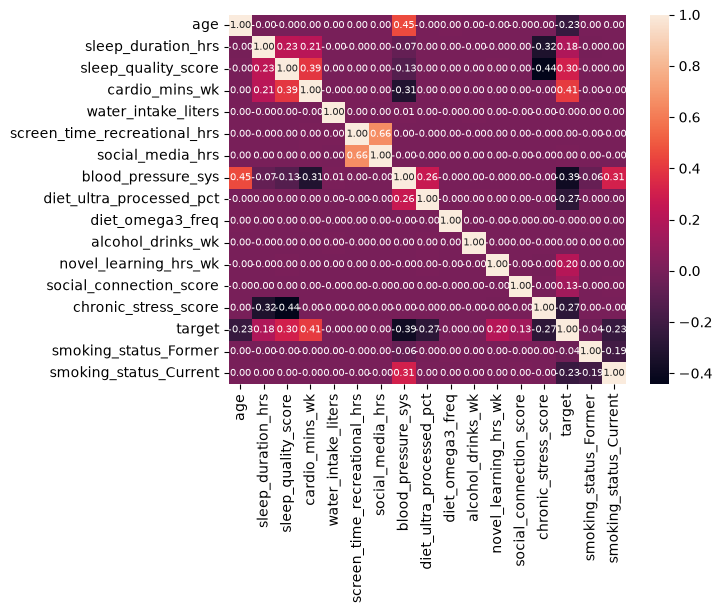

In [273]:
sns.heatmap(
    df_train_heatmap.corr(),
    annot=True,
    fmt=".2f",
    annot_kws={'size': 7}
)

### Summary 

`social_media_hrs` and `screen_time_recreational_hrs` are highly correlated, which makes sense.

### Histograms and boxplots

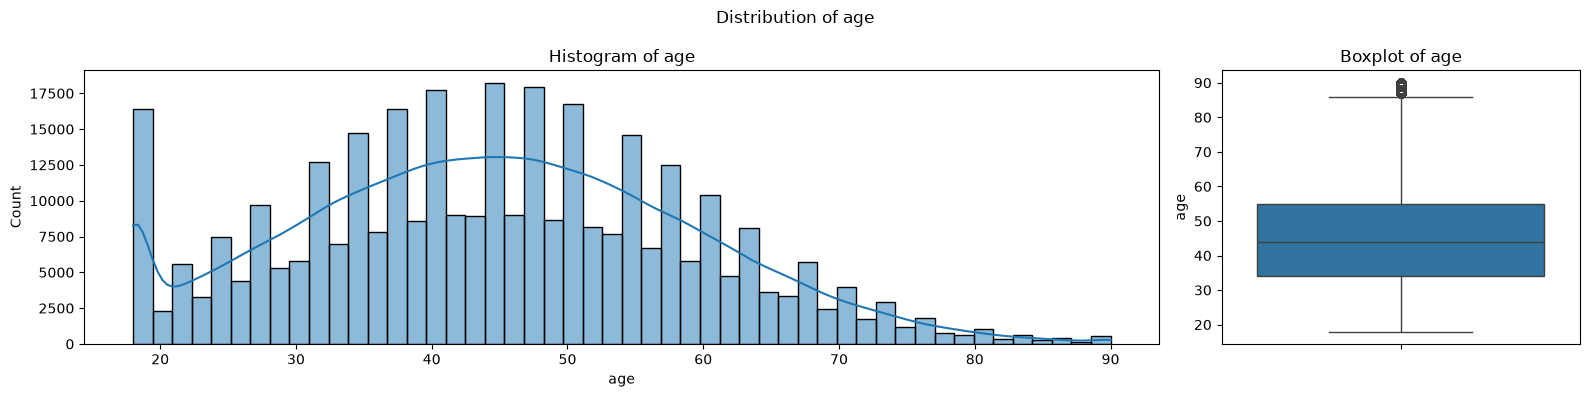

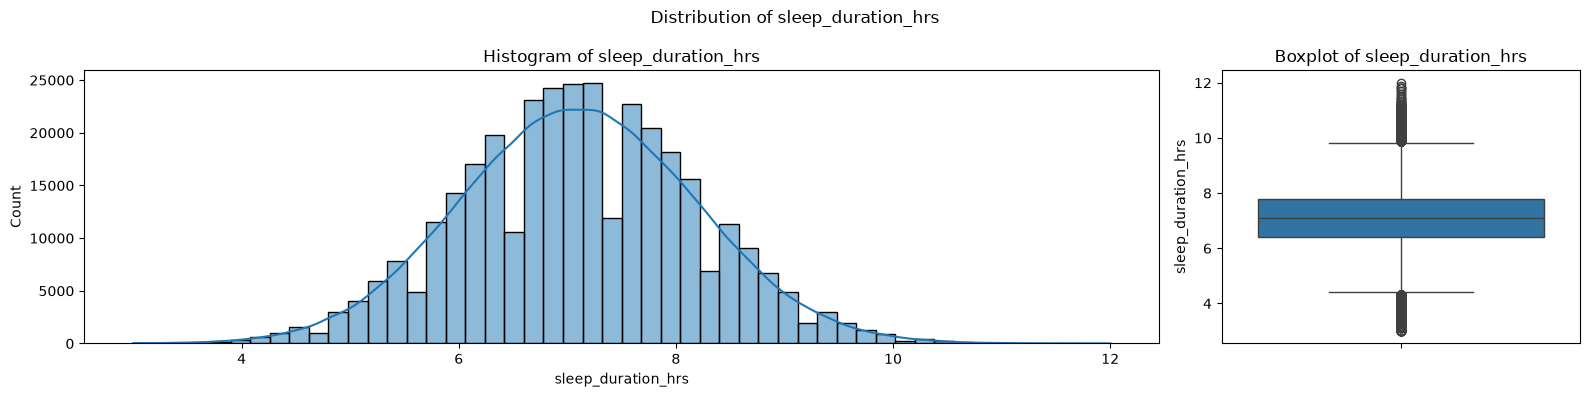

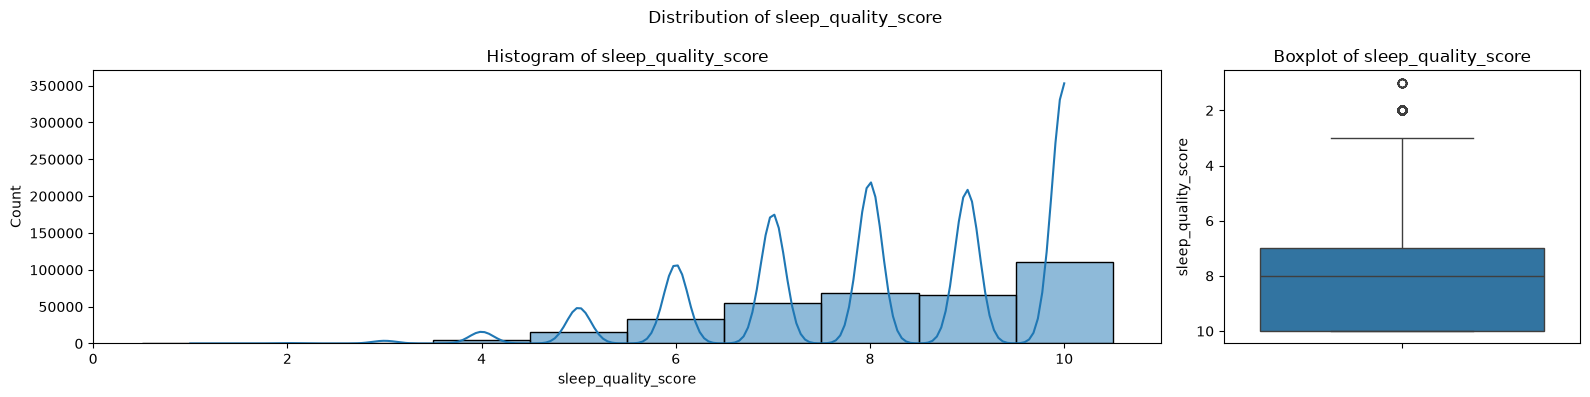

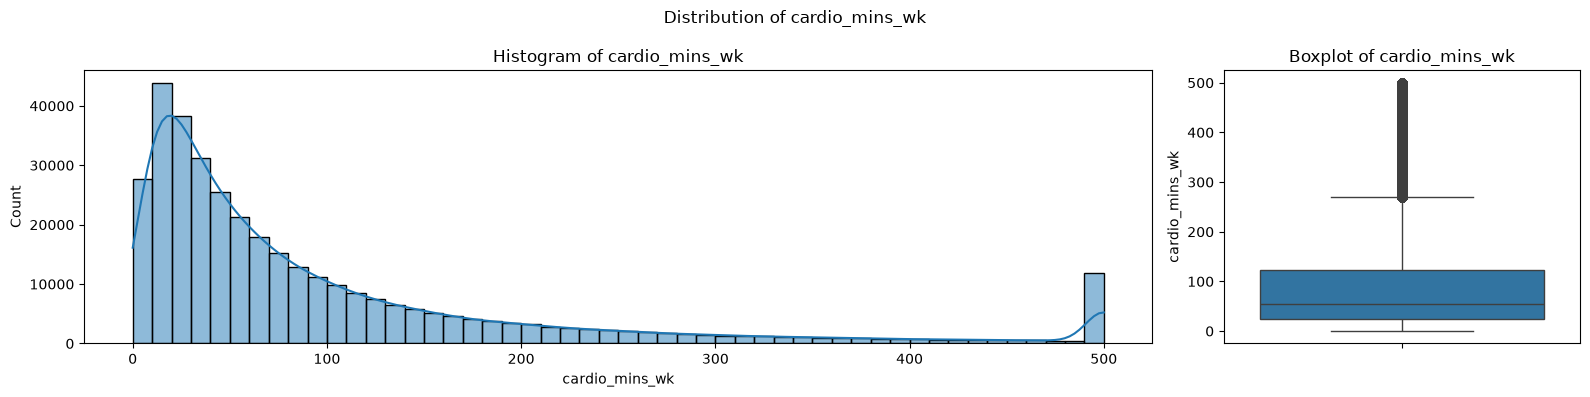

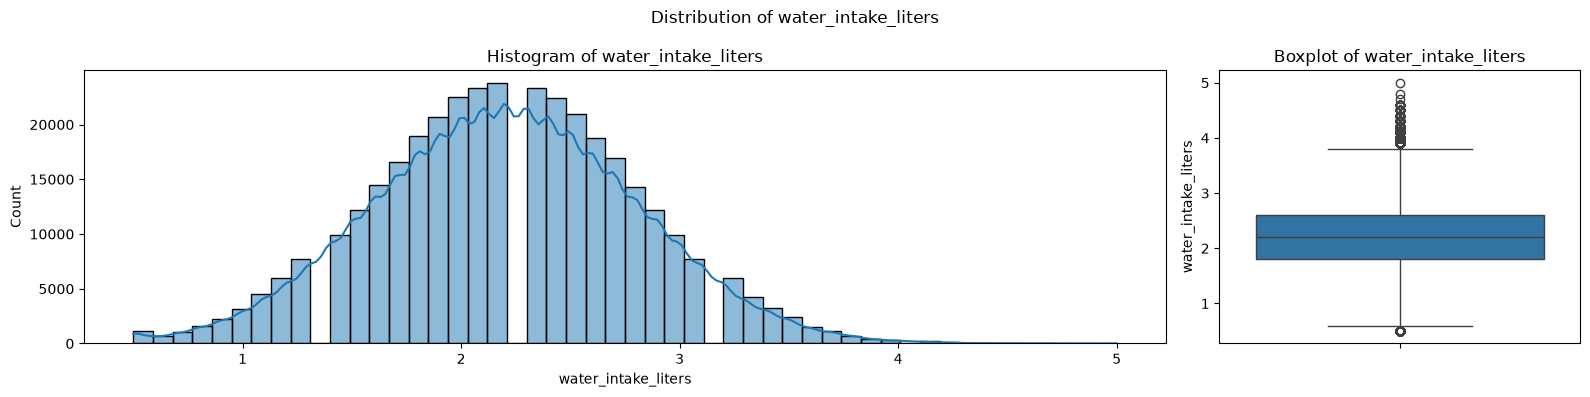

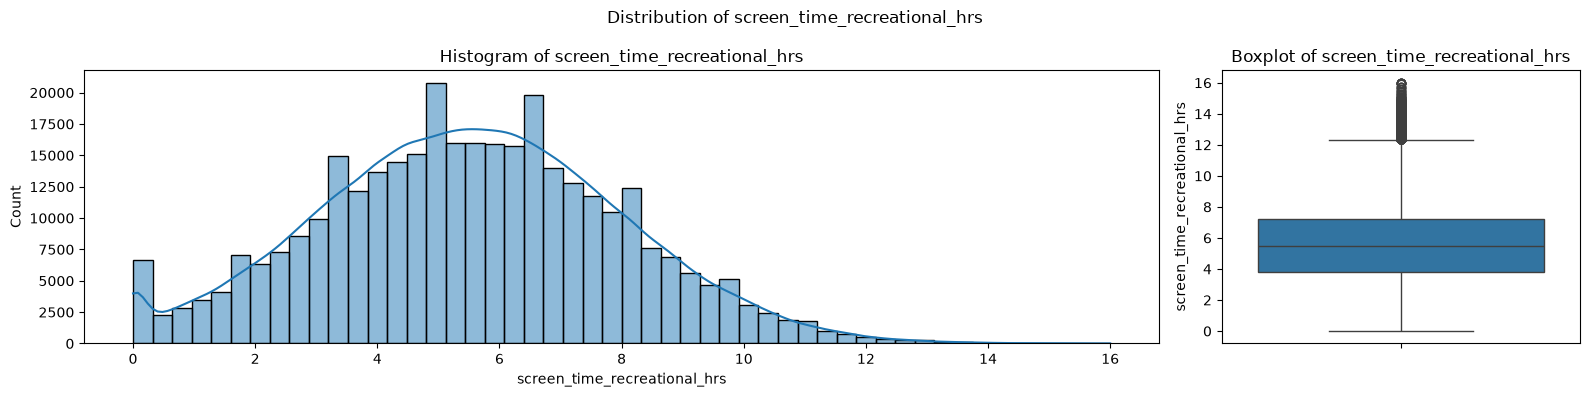

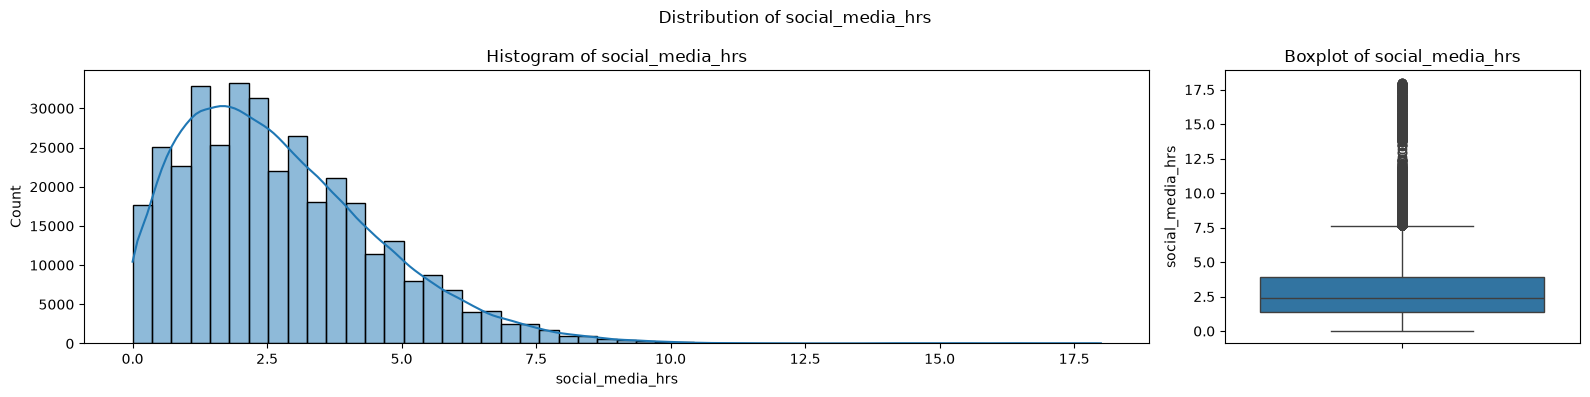

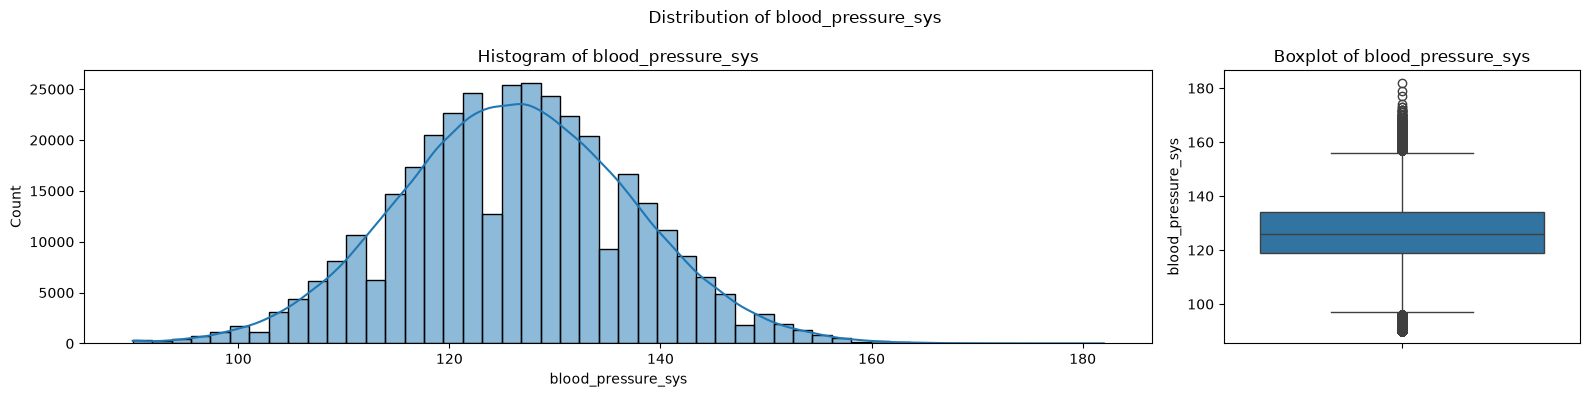

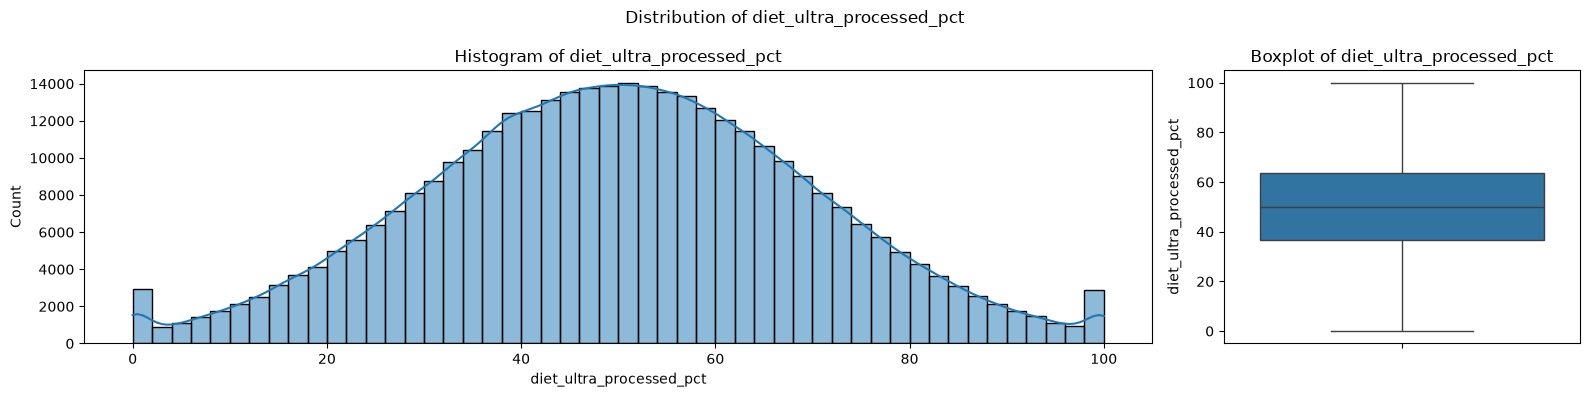

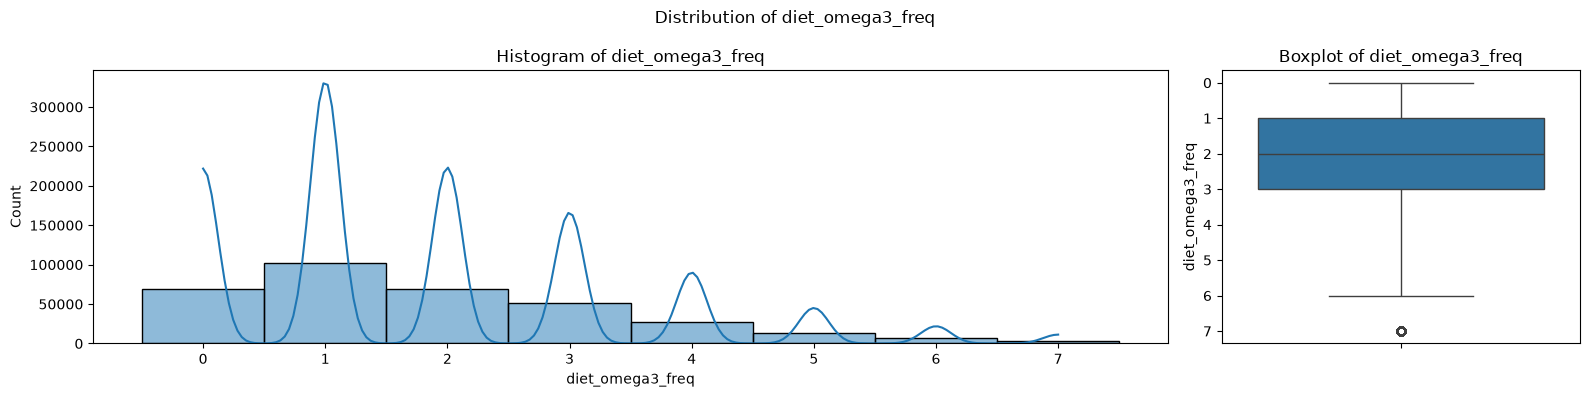

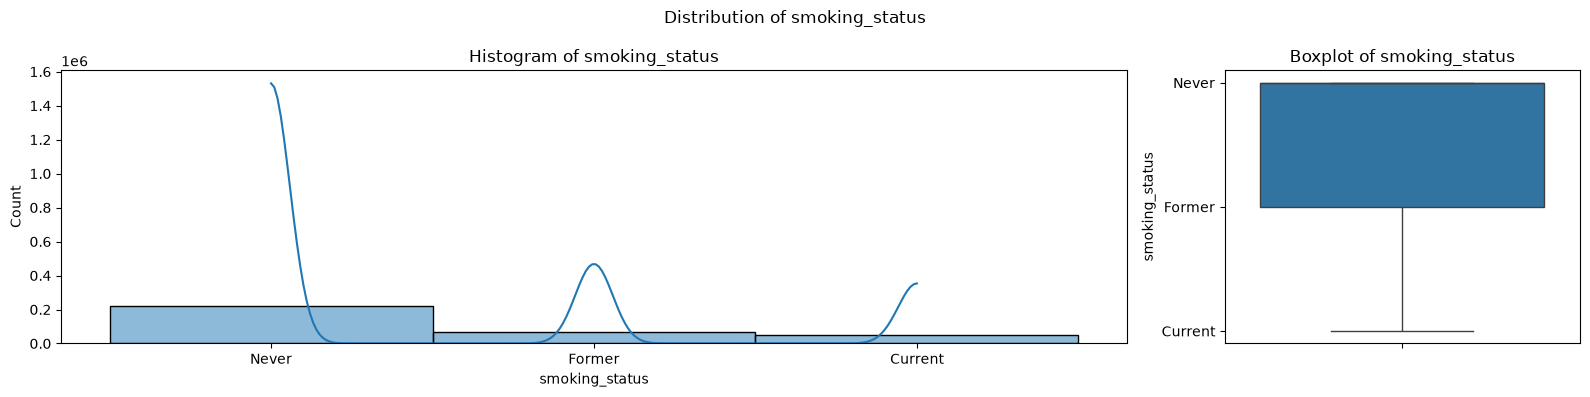

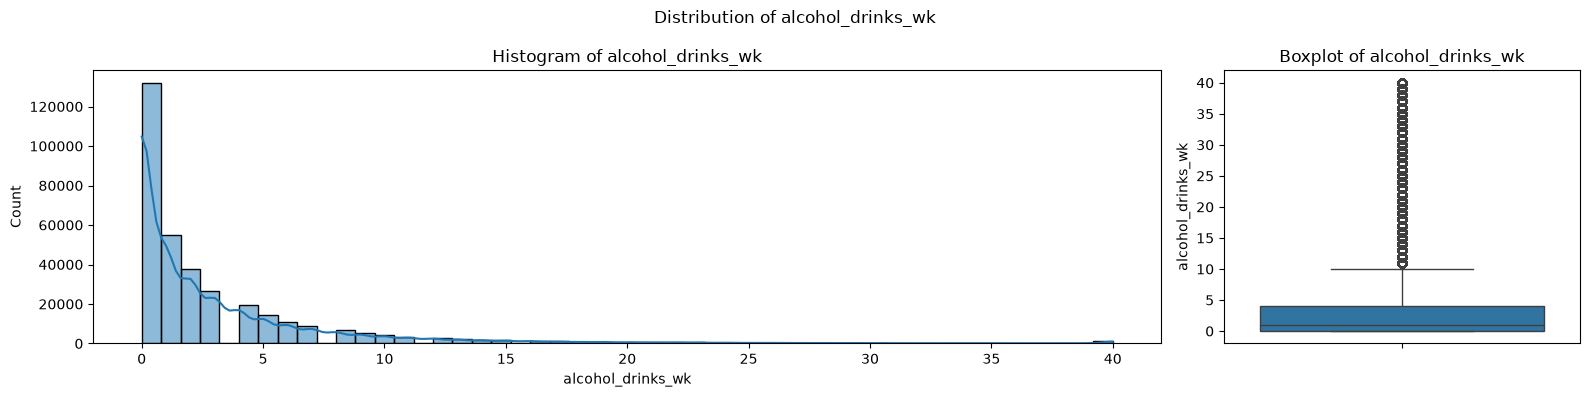

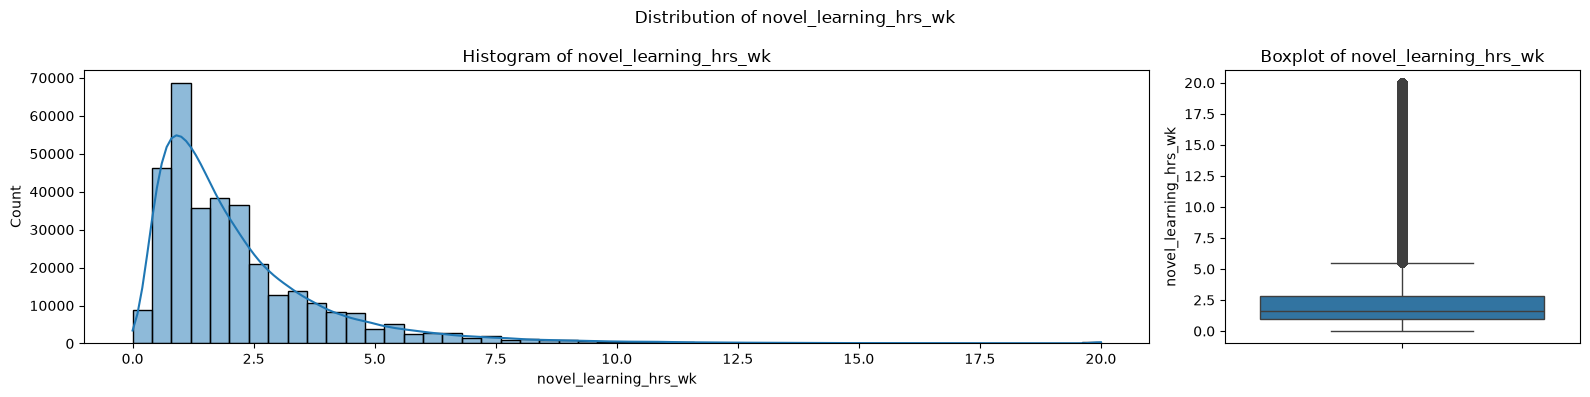

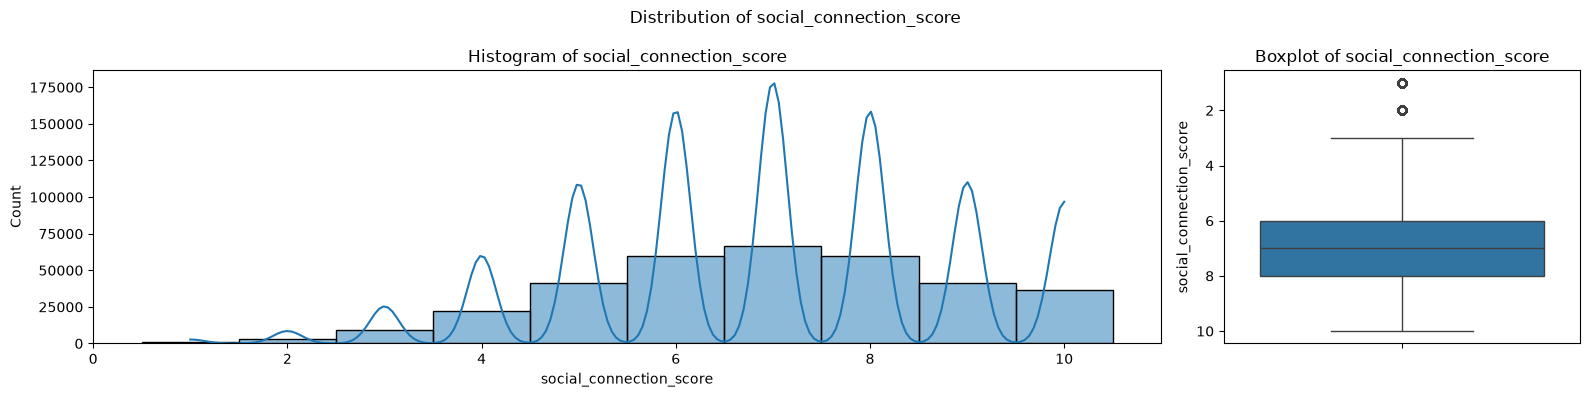

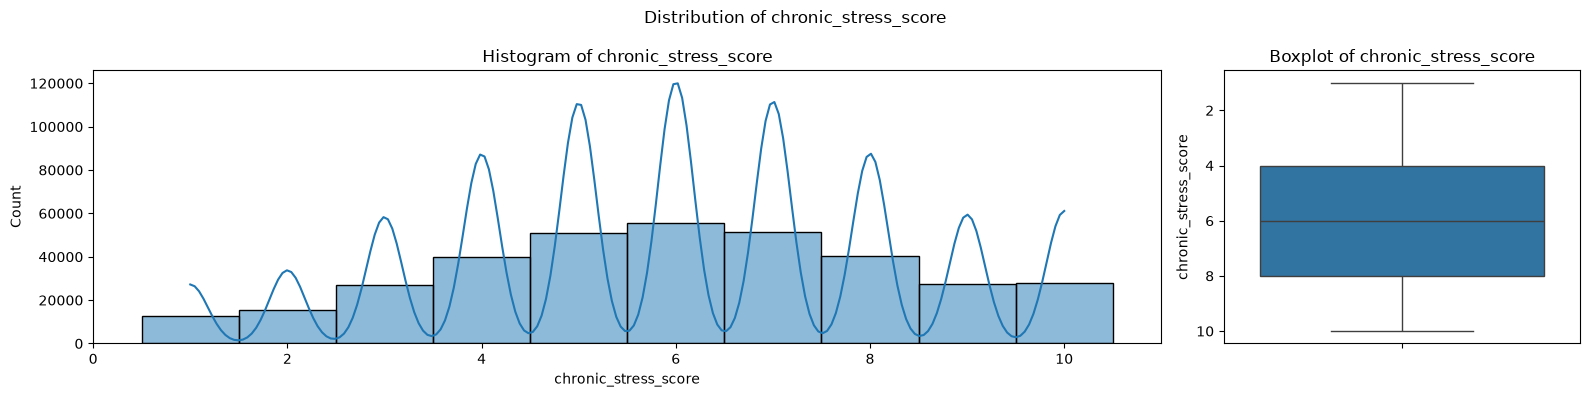

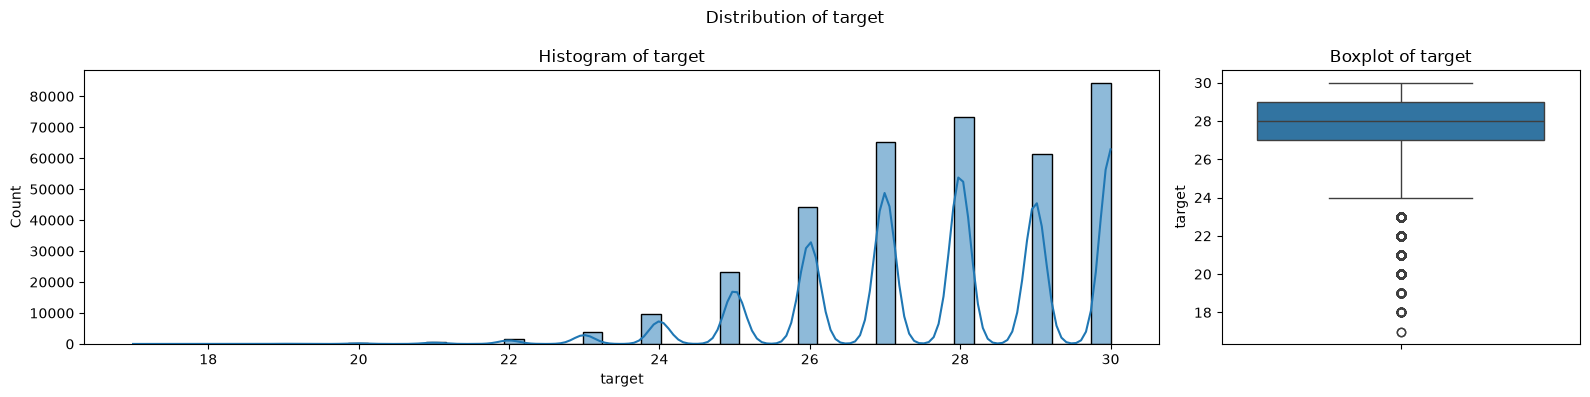

In [274]:
for feature in df_train.columns:
    if df_train[feature].dtype == 'bool': # skips boolean datatypes
        continue


    fig, axes = plt.subplots(
        1, 2, 
        figsize=(16, 4), 
        gridspec_kw={'width_ratios': [3, 1]} # ratio of graphs
    )

    # Histogram
    sns.histplot(
        data=df_train,
        x=feature,
        ax=axes[0], 
        kde=True,  # add a smooth line
        bins=50
    )
    axes[0].set_title(f'Histogram of {feature}')

    # Boxplot
    sns.boxplot(
        data=df_train,
        y=feature,
        ax=axes[1]
    )
    axes[1].set_title(f'Boxplot of {feature}')

    fig.suptitle(f'Distribution of {feature}')
    fig.tight_layout()
    plt.show()
    plt.close()

### Visualising after applying transformers

In [275]:
# features = ['novel_learning_hrs_wk', 'alcohol_drinks_wk', 'social_media_hrs', 'cardio_mins_wk']

# for feature in features:
#     df_train[feature] = np.sqrt(df_train[feature])
#     if df_train[feature].dtype == 'bool': # skips boolean datatypes
#         continue


#     fig, axes = plt.subplots(
#         1, 2, 
#         figsize=(16, 4), 
#         gridspec_kw={'width_ratios': [3, 1]} # ratio of graphs
#     )

#     # Histogram
#     sns.histplot(
#         data=df_train,
#         x=feature,
#         ax=axes[0], 
#         kde=True,  # add a smooth line
#         bins=50
#     )
#     axes[0].set_title(f'Histogram of {feature}')

#     # Boxplot
#     sns.boxplot(
#         data=df_train,
#         y=feature,
#         ax=axes[1]
#     )
#     axes[1].set_title(f'Boxplot of {feature}')

#     fig.suptitle(f'Distribution of {feature}')
#     fig.tight_layout()
#     plt.show()
#     plt.close()

Pairplot

In [276]:
# sns.pairplot(
#     df_train[:1000]
# )
# plt.show()
# plt.close()

### Summary

- `cardio_mins_wk` has a high amount of values close to 500. Might be that is the highest value possible to register, so observations at or above 500 minutes per week are situated there. Imputation?
- Will consider log transformation for feature `cardio_mins_wk`, `social_media_hrs`, `alcohol_drinks_wk`, and `novel_learning_hrs_wk`.
- Will consider changing scoring features into ordinal category datatypes.

### Split dataset

In [277]:
X = df_train.drop(columns='target')
y = df_train['target']

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    train_size=5000,
    random_state=42,
    shuffle=True,
    stratify=y
)

Numerical columns

In [278]:
numerical_features = df_train.select_dtypes(include='number').columns.drop('target').tolist()

Categorical columns

In [287]:
categorical_features = df_train.select_dtypes(include='category').columns.tolist()
print(categorical_features)

['sleep_quality_score', 'diet_omega3_freq', 'smoking_status', 'social_connection_score', 'chronic_stress_score']


# Pipeline A

# Pipeline B

# Pipeline C

Vinicius transformer pipelines

In [ ]:

# Numerical Pipeline
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Combining the pipelines with ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numerical_features),
    ('smoking', OrdinalEncoder(categories=['Never', 'Former', 'Current'], dtype=int, handle_unknown='ignore'), ['smoking_status']),
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# Numerical pipeline for tree-based models
numeric_pipeline_tree = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Preprocessor for Random Forest
preprocessor_rf = ColumnTransformer(transformers=[
    ('num', numeric_pipeline_tree, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

Transformer

In [281]:
# transformer = ColumnTransformer(
#     transformers = [
#         (
#             'encode',
#             OneHotEncoder(drop='first', handle_unknown='ignore'),
#             ['smoking_status']
#         ),
#         # (
#         #     'ordinal_encode',
#         #     OrdinalEncoder(handle_unknown='ignore'),
#         #     categorical_features
#         # )
#         # (
#         #     'impute_median',
#         #     SimpleImputer(strategy='median'),
#         #     numerical_features
#         # ),
#         # (
#         #     'impute_freq',
#         #     SimpleImputer(strategy='most_frequent'),
#         #     categorical_features),
#         # (
#         #     'impute_freq_smoke',
#         #     Pipeline([
#         #         (
#         #             'impute',
#         #             SimpleImputer(strategy='most_frequent')
#         #         ),
#         #         (
#         #             'encode',
#         #             OneHotEncoder(drop='first', handle_unknown='ignore')
#         #         ),
#         #     ]),
#         #     ['smoking_status']
#         # ),
#         # (
#         #     'log', FunctionTransformer(np.log, validate=False),
#         #     ['novel_learning_hrs_wk', 'alcohol_drinks_wk', 'social_media_hrs', 'cardio_mins_wk']
#         # )

#     ],
#     remainder='passthrough'
# )



ensemble_pipeline = Pipeline([
    ('preprocess', preprocessor_rf),
    ('rfc', RandomForestClassifier(
        random_state=42
    ))
])
ensemble_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('rfc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the out

### Random Forest Classifier Pipeline

"Is the target at 30 or not?"

In [282]:
param_grid_ensemble = {
    'rfc__n_estimators': [10, 25, 50, 100, 150, 200, 300, 400, 500],
    'rfc__max_depth': [None, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'rfc__criterion': ['gini', 'entropy', 'log_loss'],
    'rfc__min_samples_split': [2, 5, 10, 20],
    'rfc__min_samples_leaf': [1, 3, 5, 10, 20],
    'rfc__max_features': ['sqrt', 'log2'],
    'rfc__min_impurity_decrease': np.arange(0.0, 0.51, 0.01)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rcf_random_search = RandomizedSearchCV(
    n_iter=25,
    estimator=ensemble_pipeline,
    param_distributions=param_grid_ensemble,
    scoring='f1_macro',
    n_jobs=-1,
    cv=skf,
    random_state=42
)

# Filter for when y is max (30)
y_train_is_max = y_train == 30


rcf_random_search.fit(X_train, y_train_is_max)

ValueError: 
All the 250 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
250 fits failed with the following error:
Traceback (most recent call last):
  File "/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/sklearn/pipeline.py", line 632, in fit
    Xt = self._fit(
        X, y, routed_params, raw_params=params, cal

In [ ]:
print(f"Best parameters: {rcf_random_search.best_params_}")
print(f"Best score: {rcf_random_search.best_score_:.3f}")

Best parameters: {'rfc__n_estimators': 10, 'rfc__min_samples_split': 2, 'rfc__min_samples_leaf': 10, 'rfc__min_impurity_decrease': np.float64(0.0), 'rfc__max_features': 'sqrt', 'rfc__max_depth': 7, 'rfc__criterion': 'gini'}
Best score: 0.693


### Regression Pipeline

In [ ]:
regression_mask = ~y_train_is_max
X_reg_train, y_reg_train = X_train.loc[regression_mask], y_train.loc[regression_mask]

regression_pipeline = Pipeline(
    [
        ('preprocess', preprocessor),
        ('regressor', Ridge(
            random_state=42
        ))
    ]
)

param_grid_regression = {
        'regressor__alpha':    np.logspace(-3, 3, 30),
        'regressor__solver':   ['lsqr', 'sparse_cg', 'sag', 'saga'],
        'regressor__tol':      [1e-6, 1e-5, 1e-4, 1e-3],
        'regressor__max_iter': [500, 1000, 5000]
    }

cv = KFold(n_splits=5, shuffle=True, random_state=42)


# Should consider Gridsearch
reg_random_search = RandomizedSearchCV(
    n_iter=10,
    estimator=regression_pipeline,
    param_distributions=param_grid_regression,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    cv=cv,
    random_state=42
)

reg_random_search.fit(X_reg_train, y_reg_train)

/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid valu

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__alpha': array([1.0000...00000000e+03]), 'regressor__max_iter': [500, 1000, ...], 'regressor__solver': ['lsqr', 'sparse_cg', ...], 'regressor__tol': [1e-06, 1e-05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``

In [ ]:
print(f"Best parameters: {reg_random_search.best_params_}")
print(f"Best score: {-reg_random_search.best_score_:.3f}")

Best parameters: {'regressor__tol': 1e-06, 'regressor__solver': 'sparse_cg', 'regressor__max_iter': 5000, 'regressor__alpha': np.float64(22.122162910704503)}
Best score: 1.018


# Polynomial regression pipeline

In [ ]:
# Define the pipeline
poly_ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(
        degree=3,
        include_bias=False
    )),
    ('model', Ridge())
])

In [ ]:
# Define hyperparameter search space
poly_ridge_param_grid = {
    'model__alpha': [0.001, 0.01, 10, 100]
}

# Perform hyperparameter optimization
poly_ridge_search = GridSearchCV(
    estimator=poly_ridge_pipeline,
    param_grid=poly_ridge_param_grid,
    scoring='neg_mean_absolute_error',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

poly_ridge_search.fit(X_train, y_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid valu

[CV] END .................................model__alpha=0.001; total time= 1.2min


/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid valu

[CV] END ..................................model__alpha=0.01; total time= 1.2min


/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid valu

... (24 outputs left out)

[CV] END ..................................model__alpha=0.01; total time=  47.9s


/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid valu

[CV] END ..................................model__alpha=0.01; total time=  53.2s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search

# Evaluate function

In [ ]:
def evaluate_regression(
    model,
    X_train,
    X_test,
    y_train,
    y_test
):
    """Evaluate a regression model on training and test data."""

    # Generate predictions
    y_train_pred = np.asarray(model.predict(X_train)).ravel()
    y_test_pred = np.asarray(model.predict(X_test)).ravel()

    # Calculate test metrics
    mae = mean_absolute_error(y_test, y_test_pred)
    mse = mean_squared_error(y_test, y_test_pred)
    r2 = r2_score(y_test, y_test_pred)

    # Compare training and test MAE
    mae_train = mean_absolute_error(y_train, y_train_pred)
    mae_test = mean_absolute_error(y_test, y_test_pred)
    mae_difference = mae_test - mae_train

    return {
        'MAE': mae,
        'MSE': mse,
        'R²': r2,
        'Training MAE': mae_train,
        'Test MAE': mae_test,
        'MAE difference': mae_difference
    }

In [ ]:
print(evaluate_regression(reg_random_search.best_estimator_, X_train, X_val, y_train, y_val))

/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)


{'MAE': 1.1367001601009525, 'MSE': 1.9994807620318722, 'R²': 0.3841850093197846, 'Training MAE': 1.1089560398074267, 'Test MAE': 1.1367001601009525, 'MAE difference': 0.027744120293525798}


In [ ]:
print(evaluate_regression(poly_ridge_search.best_estimator_, X_train, X_val, y_train, y_val))
print(poly_ridge_search.best_params_)

/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)
/home/stig/Documents/Utdanning/DAT200/dat200-ca5/.venv/lib/python3.14/site-packages/pandas/core/arrays/categorical.py:1941: RuntimeWarning: invalid value encountered in cast
  return np.asarray(ret, dtype=dtype)


{'MAE': 1.1676688159374815, 'MSE': 2.2638136421646746, 'R²': 0.30277379836617735, 'Training MAE': 0.597271686529532, 'Test MAE': 1.1676688159374815, 'MAE difference': 0.5703971294079495}
{'model__alpha': 100}


# Model comparison and evaluation

# Kaggle submission